In [122]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import numpy as np
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report,confusion_matrix,ConfusionMatrixDisplay

In [123]:
df = pd.read_csv('./dataset/diabetes_risk.csv')

In [124]:
df.head()

,patient_id,age,gender,city,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,income_bracket,diabetes_risk
0,1,47,Female,Mumbai,26.5,Yes,Sedentary,Vegetarian,Never,Never,9.0,8,178,7.3,146,90,107.1,High,Low
1,2,53,Female,Mumbai,20.5,Yes,Moderate,Vegetarian,Never,Never,7.0,6,152,6.9,156,100,93.8,Low,Low
2,3,47,Male,Thane,31.3,No,Moderate,Non-Vegetarian,Current,Regular,7.0,7,168,6.6,150,102,113.5,Low,High
3,4,41,Male,Bengaluru,22.8,No,Sedentary,Non-Vegetarian,Never,Never,9.0,5,155,6.7,126,92,109.6,Middle,Low
4,5,57,Female,Bengaluru,16.7,No,Sedentary,Non-Vegetarian,Current,Occasional,6.5,10,188,6.7,130,90,80.8,High,Low


In [125]:
scaler = StandardScaler()
df['age'] = scaler.fit_transform(df[['age']])
df['bmi'] = scaler.fit_transform(df[['bmi']])
df['stress_level'] = scaler.fit_transform(df[['stress_level']])
df['hours_sleep_per_night'] = scaler.fit_transform(df[['hours_sleep_per_night']])
# df['credit_score'] = scaler.fit_transform(df[['credit_score']])
df['waist_circumference_cm'] = scaler.fit_transform(df[['waist_circumference_cm']])
df['hba1c_level'] = scaler.fit_transform(df[['hba1c_level']])
df['blood_pressure_diastolic'] = scaler.fit_transform(df[['blood_pressure_diastolic']])
df['blood_pressure_systolic'] = scaler.fit_transform(df[['blood_pressure_systolic']])
df['fasting_blood_sugar'] = scaler.fit_transform(df[['fasting_blood_sugar']])

In [126]:
# df.info()
del df['gender']
del df['city']
del df['diet_type']
del df['income_bracket']
del df['patient_id']

In [127]:
diabetes_map = {
    "Low": 0,
    "Moderate": 1,
    "High": 2
}

df["diabetes_risk"] = df["diabetes_risk"].map(diabetes_map)

In [128]:
df.shape

(15000, 14)

In [129]:
# ages = df.loc[
#     df["alcohol_consumption"].isin(["Regular",'Occasional']),
#     "age"
# ]

# average = ages.mean()
# print(average)

In [130]:
# df.loc[
#     (df["age"] > 40) & (df["smoking_status"].isna()),
#     "smoking_status"
# ] = "Current"

In [131]:
df.loc[
    (df["smoking_status"] == "Never") & (df["alcohol_consumption"].isna()),
    "alcohol_consumption"
] = "Never"

In [132]:
# df.loc[
#     (df["alcohol_consumption"] == "Never") & (df["smoking_status"].isna()),
#     "smoking_status"
# ]

In [133]:
# df.loc[
#     (df["age"] > 40) & (df["alcohol_consumption"].isna()),
#     "alcohol_consumption"
# ] = "Regular"


In [134]:
df.isnull().sum()

age                            0
bmi                            0
family_history_diabetes        0
physical_activity_level        0
smoking_status               472
alcohol_consumption         1243
hours_sleep_per_night          0
stress_level                   0
fasting_blood_sugar            0
hba1c_level                    0
blood_pressure_systolic        0
blood_pressure_diastolic       0
waist_circumference_cm         0
diabetes_risk                  0
dtype: int64

In [135]:
df = df.dropna()

In [136]:
# cross_tab = pd.crosstab(
#     df["smoking_status"],
#     df["alcohol_consumption"]
# )

# sns.heatmap(
#     cross_tab,
#     annot=True,
#     fmt="d",
#     cmap="Blues"
# )

# plt.xlabel("Alcohol Consumption")
# plt.ylabel("Smoking Status")
# plt.title("Smoking Status vs Alcohol Consumption")
# plt.show()

In [137]:
# ages = df.loc[df["alcohol_consumption"].isin(["Regular",'Occasional']),"age"]

# average = ages.mean()
# print(average)

In [138]:
activity_map = {
    "Sedentary": 0,
    "Moderate": 1,
    "Active": 2
}

df["physical_activity_level"] = df["physical_activity_level"].map(activity_map)

In [139]:
column1 = pd.get_dummies(df['family_history_diabetes']).astype(int)

In [140]:
del df['family_history_diabetes']

In [141]:
df = pd.concat([df,column1],axis=1)

In [142]:
df.columns

Index(['age', 'bmi', 'physical_activity_level', 'smoking_status',
       'alcohol_consumption', 'hours_sleep_per_night', 'stress_level',
       'fasting_blood_sugar', 'hba1c_level', 'blood_pressure_systolic',
       'blood_pressure_diastolic', 'waist_circumference_cm', 'diabetes_risk',
       'No', 'Yes'],
      dtype='str')

In [143]:
smokers_map = {
    "Never": 0,
    "Former": 1,
    "Current": 2
}

df["smoking_status"] = df["smoking_status"].map(smokers_map)

In [144]:
alcohol_map = {
    "Never": 0,
    "Occasional": 1,
    "Regular": 2
}

df["alcohol_consumption"] = (
    df["alcohol_consumption"]
    .map(alcohol_map)
   
)

In [145]:
df.columns

Index(['age', 'bmi', 'physical_activity_level', 'smoking_status',
       'alcohol_consumption', 'hours_sleep_per_night', 'stress_level',
       'fasting_blood_sugar', 'hba1c_level', 'blood_pressure_systolic',
       'blood_pressure_diastolic', 'waist_circumference_cm', 'diabetes_risk',
       'No', 'Yes'],
      dtype='str')

In [146]:
# df['diabetes_risk']

In [147]:
Y= df['diabetes_risk']

In [148]:
del df['diabetes_risk']

In [149]:
X = df

In [150]:
X.columns

Index(['age', 'bmi', 'physical_activity_level', 'smoking_status',
       'alcohol_consumption', 'hours_sleep_per_night', 'stress_level',
       'fasting_blood_sugar', 'hba1c_level', 'blood_pressure_systolic',
       'blood_pressure_diastolic', 'waist_circumference_cm', 'No', 'Yes'],
      dtype='str')

In [151]:
X.isnull().sum()

age                         0
bmi                         0
physical_activity_level     0
smoking_status              0
alcohol_consumption         0
hours_sleep_per_night       0
stress_level                0
fasting_blood_sugar         0
hba1c_level                 0
blood_pressure_systolic     0
blood_pressure_diastolic    0
waist_circumference_cm      0
No                          0
Yes                         0
dtype: int64

In [102]:
# model = SVC(kernel='linear',C=1)



In [103]:
model = LogisticRegression()


In [104]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    # random_state=42,
)

In [105]:

from sklearn.model_selection import cross_val_score 

log_model = LogisticRegression(max_iter=1000) 
log_scores = cross_val_score(log_model, X_train, y_train, cv=5) 
print("Accuracy for each of the 5 folds:", log_scores)

Accuracy for each of the 5 folds: [0.80307979 0.79701353 0.80027998 0.79328045 0.78581428]


In [106]:
model.fit(X_train,y_train)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [116]:
model.coef_

array([[-6.43670449e-01, -4.80661247e-01, -1.63248830e-02,
        -1.79258719e-02, -5.75857135e-02, -3.84087045e-02,
        -1.18864243e-02, -1.71599462e+00, -1.48042622e+00,
         3.60928467e-02, -1.27226675e-02,  2.61500968e-02,
         8.46223248e-01,  3.11745724e-01],
       [ 1.08593320e-02, -4.31154681e-02,  5.77534650e-03,
        -2.01060705e-03,  2.14963616e-02,  1.19337532e-03,
         2.67980213e-02, -5.25564899e-02,  9.01955345e-03,
        -9.14620255e-03,  9.67517489e-03,  2.67162605e-02,
         2.56572751e-01,  3.29858645e-01],
       [ 6.32811117e-01,  5.23776715e-01,  1.05495365e-02,
         1.99364789e-02,  3.60893519e-02,  3.72153291e-02,
        -1.49115969e-02,  1.76855111e+00,  1.47140667e+00,
        -2.69466441e-02,  3.04749266e-03, -5.28663573e-02,
        -1.10279600e+00, -6.41604369e-01]])

In [110]:
y_pred = model.predict(X_test)

In [111]:
len(y_pred)

2679

In [109]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.7980589772303098
              precision    recall  f1-score   support

           0       0.86      0.91      0.88      1593
           1       0.63      0.58      0.60       695
           2       0.82      0.73      0.77       391

    accuracy                           0.80      2679
   macro avg       0.77      0.74      0.75      2679
weighted avg       0.79      0.80      0.79      2679



### Logistic

In [1111]:
'''
dropping data rows.
Accuracy: 0.7381845461365342
              precision    recall  f1-score   support

           0       0.82      0.88      0.85      1565
           1       0.51      0.46      0.48       681
           2       0.74      0.65      0.69       420

    accuracy                           0.74      2666
   macro avg       0.69      0.66      0.68      2666
weighted avg       0.73      0.74      0.73      2666
'''

'''
Normalized data without dropping data rows.
Accuracy: 0.7988055244494214
              precision    recall  f1-score   support

           0       0.86      0.91      0.88      1615
           1       0.62      0.58      0.60       669
           2       0.82      0.72      0.77       395

    accuracy                           0.80      2679
   macro avg       0.77      0.74      0.75      2679
weighted avg       0.79      0.80      0.80      2679
'''

'''
Normalized data with dropping data rows.
Accuracy: 0.8046082949308756
              precision    recall  f1-score   support

           0       0.87      0.91      0.89      1293
           1       0.62      0.59      0.61       543
           2       0.81      0.73      0.77       334

    accuracy                           0.80      2170
   macro avg       0.77      0.74      0.76      2170
weighted avg       0.80      0.80      0.80      2170

'''

print("")

### SVC

In [ ]:
'''
Dropping null data rows
Accuracy: 0.7891972993248312
              precision    recall  f1-score   support

           0       0.85      0.90      0.87      1571
           1       0.61      0.57      0.59       696
           2       0.84      0.73      0.78       399

    accuracy                           0.79      2666
   macro avg       0.77      0.73      0.75      2666
weighted avg       0.79      0.79      0.79      2666

'''

'''
Normalize data without dropping all null rows
Accuracy: 0.7876073161627473
              precision    recall  f1-score   support

           0       0.86      0.90      0.88      1598
           1       0.59      0.58      0.58       677
           2       0.83      0.70      0.76       404

    accuracy                           0.79      2679
   macro avg       0.76      0.73      0.74      2679
weighted avg       0.79      0.79      0.79      2679

'''

'''
Noramalized with dropping all null rows
Accuracy: 0.7995391705069125
              precision    recall  f1-score   support

           0       0.86      0.90      0.88      1302
           1       0.63      0.60      0.61       561
           2       0.82      0.73      0.77       307

    accuracy                           0.80      2170
   macro avg       0.77      0.74      0.76      2170
weighted avg       0.80      0.80      0.80      2170

'''



x_test

In [629]:
len(y_test)

2170

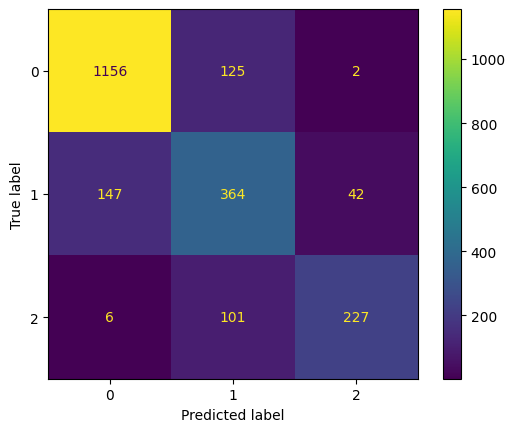

In [630]:
cm = confusion_matrix(y_test,y_pred,labels=model.classes_)
ConfusionMatrixDisplay(confusion_matrix =cm,display_labels = model.classes_).plot()